### **Session 9 · Notebook 3 — Encoder–decoder with LSTM**

Session 9 deck, *Working with RNN (II): machine translation*. Run in Colab with a GPU (Runtime → Change runtime type → T4 GPU).

| Notebook | Model |
|---|---|
| 01 | aligned LSTM |
| 02 | encoder–decoder with GRU |
| **03** | **encoder–decoder with LSTM** |
| 04 | bidirectional LSTM encoder |
| 05 | Sutskever et al. (2014): deep LSTM, reversed source, beam search |


The same encoder–decoder as Notebook 2, with **LSTM** cells instead of GRU. An LSTM has two states, the
hidden state $h$ and the cell state $c$ (the "conveyor belt" of Session 7), so the encoder hands **both**
to the decoder. Everything else is identical: same data, same sizes, same training.

In [1]:
import os
os.environ.setdefault("KERAS_BACKEND", "tensorflow")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")      # hide TensorFlow info messages
import json, time, re, math, collections
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers, ops
print("Keras", keras.__version__, "| TensorFlow", tf.__version__,
      "| GPU:", tf.config.list_physical_devices("GPU"))
keras.utils.set_random_seed(42)
os.makedirs("results", exist_ok=True)

I0000 00:00:1792183306.194276    5258 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792183307.575168    5258 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Keras 3.12.3 | TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
DATA_DIR = "data"          # where Notebook 1 saved pairs.tsv (see the note above for Colab + Drive)
VOCAB = 15000              # words kept in each language (the rest become [UNK])
SRC_LEN = 12               # English: at most 10 words, padded to 12
TGT_LEN = 13               # Spanish: [start] + at most 10 words + [end], padded to 13
EMB = 256                  # size of the word vectors
BATCH = 64
EPOCHS = 20                # maximum; EarlyStopping usually stops earlier
QUICK = False              # True: a short trial run (few batches, 2 epochs) to check that the code works

**Colab tip.** Every Colab notebook runs on its own machine, so a file saved by Notebook 1 is not
visible from Notebook 2. To share the data, mount your Google Drive in every notebook and point
`DATA_DIR` to the same Drive folder:

```python
from google.colab import drive
drive.mount("/content/drive")
DATA_DIR = "/content/drive/MyDrive/DL26/session9/data"
```
(Or simply upload `data/pairs.tsv`, created by Notebook 1, to the `data/` folder of this notebook.)

## 1. The data (saved by Notebook 1)

In [3]:
path = os.path.join(DATA_DIR, "pairs.tsv")
if not os.path.exists(path):
    raise FileNotFoundError(f"{path} not found: run Notebook 1 first (or copy its data/ folder here).")
pairs = pd.read_csv(path, sep="\t", keep_default_na=False)
train = pairs[pairs.split == "train"]
val   = pairs[pairs.split == "val"]
test  = pairs[pairs.split == "test"]
print(f"train {len(train):,} | val {len(val):,} | test {len(test):,} pairs")
pairs.sample(5, random_state=1)

train 50,000 | val 5,000 | test 5,000 pairs


,en,es,split
15281,even a child can answer it,incluso un niño puede responderlo,train
21435,whatll they think of next,en qué pensarán después,train
44536,this pan has several uses,esta sartén tiene muchos usos,train
13518,he watches tv every day,él ve la televisión todos los días,train
47529,i dont have a computer,no tengo un ordenador,train


## 2. Text to numbers, and teacher forcing

In [4]:
def prepare_source(sentence):
    return sentence          # Notebook 5 will change this (reversed word order)

In [5]:
# Text -> integers. The text is already clean (lower case, no punctuation), so we only split on spaces.
# Index 0 is padding, index 1 is [UNK] (unknown word).
src_vec = layers.TextVectorization(VOCAB, standardize=None, output_sequence_length=SRC_LEN)
tgt_vec = layers.TextVectorization(VOCAB, standardize=None, output_sequence_length=TGT_LEN)
src_vec.adapt(train.en.map(prepare_source).values)        # vocabularies from the TRAINING set only
tgt_vec.adapt(("[start] " + train.es + " [end]").values)
src_words = src_vec.get_vocabulary()
tgt_words = tgt_vec.get_vocabulary()
START, END = tgt_words.index("[start]"), tgt_words.index("[end]")
N_SRC, N_TGT = len(src_words), len(tgt_words)            # real vocabulary sizes (at most VOCAB)
print("English vocabulary:", N_SRC, "| Spanish vocabulary:", N_TGT)
print("first Spanish words:", tgt_words[:12])

English vocabulary: 9368 | Spanish vocabulary: 15000
first Spanish words: ['', '[UNK]', np.str_('[start]'), np.str_('[end]'), np.str_('de'), np.str_('no'), np.str_('tom'), np.str_('a'), np.str_('que'), np.str_('la'), np.str_('el'), np.str_('es')]


In [6]:
def make_dataset(df, shuffle=False):
    src = src_vec(df.en.map(prepare_source).values)                  # (n, 12)
    tgt = tgt_vec(("[start] " + df.es + " [end]").values)           # (n, 13)
    # TEACHER FORCING: the decoder reads the correct previous word and predicts the next one
    #   decoder input : [start] yo  tengo hambre
    #   target        : yo      tengo hambre [end]
    ds = tf.data.Dataset.from_tensor_slices(((src, tgt[:, :-1]), tgt[:, 1:]))
    if shuffle:
        ds = ds.shuffle(20000, seed=42)
    ds = ds.batch(BATCH)
    if QUICK:
        ds = ds.take(20)
    return ds.prefetch(tf.data.AUTOTUNE)

train_ds, val_ds = make_dataset(train, shuffle=True), make_dataset(val)

(x_src, x_dec), y = next(iter(train_ds))
i = 0
print("English      :", " ".join(src_words[t] for t in x_src[i].numpy() if t))
print("decoder input:", " ".join(tgt_words[t] for t in x_dec[i].numpy() if t))
print("target       :", " ".join(tgt_words[t] for t in y[i].numpy() if t))

English      : i should be there by 2 30
decoder input: [start] debería estar allí para las dos y media [end]
target       : debería estar allí para las dos y media [end]


## 3. The model
```
 English ──► Embedding ──► LSTM encoder ──► (h, c)
                                              │ initial state
 [start] yo tengo ──► Embedding ──► LSTM decoder ──► Dense(15,000) ──► yo tengo hambre
```

In [7]:
NAME, MODEL_LABEL = "nb3", "encoder-decoder LSTM"
UNITS = 512

enc_in = keras.Input(shape=(SRC_LEN,), dtype="int64", name="english")
x = layers.Embedding(N_SRC, EMB, mask_zero=True)(enc_in)
_, h, c = layers.LSTM(UNITS, return_state=True, name="encoder")(x)     # two states: h and c

dec_in = keras.Input(shape=(TGT_LEN - 1,), dtype="int64", name="spanish_so_far")
y = layers.Embedding(N_TGT, EMB, mask_zero=True)(dec_in)
y = layers.LSTM(UNITS, return_sequences=True, name="decoder")(y, initial_state=[h, c])
outputs = layers.Dense(N_TGT, name="next_word")(y)

model = keras.Model([enc_in, dec_in], outputs, name="seq2seq_lstm")
model.summary()

Model: "seq2seq_lstm"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ english             │ (None, 12)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spanish_so_far      │ (None, 12)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 12, 256)   │  2,398,208 │ english[0][0]     │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 12)        │          0 │ english[0][0]     │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 12, 256)   │  3,840,000 │ spanish_so_far[0… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder (LSTM)      │ [(None, 512),     │  1,574,912 │ embedding[0][0],  │
│                     │ (None, 512),      │            │ not_equal[0][0]   │
│                     │ (None, 512)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder (LSTM)      │ (None, 12, 512)   │  1,574,912 │ embedding_1[0][0… │
│                     │                   │            │ encoder[0][1],    │
│                     │                   │            │ encoder[0][2]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ next_word (Dense)   │ (None, 12, 15000) │  7,695,000 │ decoder[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 17,083,032 (65.17 MB)

 Trainable params: 17,083,032 (65.17 MB)

 Non-trainable params: 0 (0.00 B)

## 4. Train

In [8]:
# Padding (index 0) must not count: the loss ignores class 0, and so does the accuracy.
loss_fn = keras.losses.SparseCategoricalCrossentropy(from_logits=True, ignore_class=0)

class MaskedAccuracy(keras.metrics.Metric):
    """Fraction of real words (not padding) predicted correctly."""
    def __init__(self, name="masked_acc", **kwargs):
        super().__init__(name=name, **kwargs)
        self.correct = self.add_variable(shape=(), initializer="zeros", name="correct")
        self.total = self.add_variable(shape=(), initializer="zeros", name="total")

    def update_state(self, y_true, y_pred, sample_weight=None):
        y_true = ops.cast(y_true, "int32")
        pred = ops.cast(ops.argmax(y_pred, axis=-1), "int32")
        mask = ops.cast(y_true != 0, "float32")
        self.correct.assign_add(ops.sum(ops.cast(pred == y_true, "float32") * mask))
        self.total.assign_add(ops.sum(mask))

    def result(self):
        return self.correct / ops.maximum(self.total, 1.0)

    def reset_state(self):
        self.correct.assign(0.0); self.total.assign(0.0)

In [9]:
model.compile(optimizer=keras.optimizers.Adam(1e-3, clipnorm=1.0),   # clipping: Session 7
              loss=loss_fn, metrics=[MaskedAccuracy()])
callbacks = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)]
t0 = time.time()
history = model.fit(train_ds, validation_data=val_ds, epochs=2 if QUICK else EPOCHS,
                    callbacks=callbacks, verbose=2)
minutes = (time.time() - t0) / 60
epochs_run = len(history.history["loss"])
print(f"training time: {minutes:.1f} min, {60 * minutes / epochs_run:.0f} s/epoch, {epochs_run} epochs")
model.save_weights(f"results/{NAME}.weights.h5")

Epoch 1/20
782/782 - 51s - 65ms/step - loss: 5.3323 - masked_acc: 0.2277 - val_loss: 4.4179 - val_masked_acc: 0.2857
Epoch 2/20
782/782 - 46s - 59ms/step - loss: 3.9408 - masked_acc: 0.3536 - val_loss: 3.4571 - val_masked_acc: 0.4036
Epoch 3/20
782/782 - 49s - 62ms/step - loss: 3.0191 - masked_acc: 0.4526 - val_loss: 2.9547 - val_masked_acc: 0.4665
Epoch 4/20
782/782 - 46s - 59ms/step - loss: 2.3552 - masked_acc: 0.5276 - val_loss: 2.6635 - val_masked_acc: 0.5132
Epoch 5/20
782/782 - 47s - 60ms/step - loss: 1.8260 - masked_acc: 0.6018 - val_loss: 2.4732 - val_masked_acc: 0.5445
Epoch 6/20
782/782 - 49s - 62ms/step - loss: 1.3994 - masked_acc: 0.6781 - val_loss: 2.3892 - val_masked_acc: 0.5614
Epoch 7/20
782/782 - 47s - 59ms/step - loss: 1.0672 - masked_acc: 0.7494 - val_loss: 2.3466 - val_masked_acc: 0.5728
Epoch 8/20
782/782 - 49s - 63ms/step - loss: 0.8192 - masked_acc: 0.8065 - val_loss: 2.3528 - val_masked_acc: 0.5799
Epoch 9/20
782/782 - 49s - 62ms/step - loss: 0.6321 - masked_acc

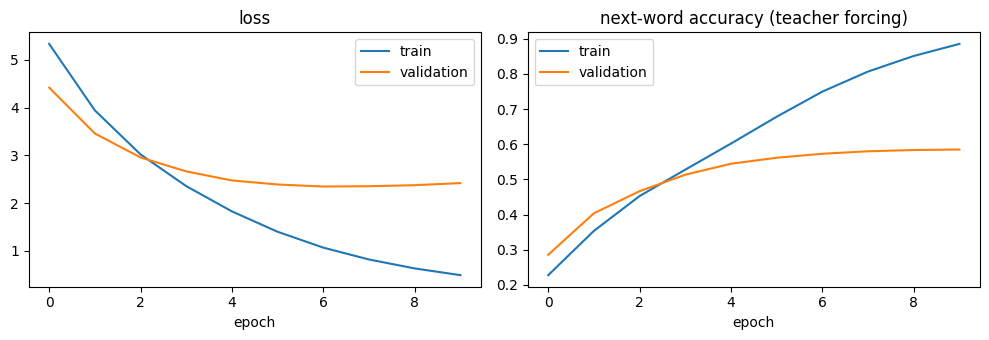

In [10]:
h = history.history
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(h["loss"], label="train"); ax[0].plot(h["val_loss"], label="validation")
ax[0].set_title("loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(h["masked_acc"], label="train"); ax[1].plot(h["val_masked_acc"], label="validation")
ax[1].set_title("next-word accuracy (teacher forcing)"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.savefig(f"results/{NAME}_curves.png", dpi=150); plt.show()

## 5. Translate (greedy decoding)
In training the decoder reads the *correct* previous word (teacher forcing). When we translate there is no
correct answer: the decoder must read **its own** previous word. So translation is a loop:
`[start]` → predict a word → append it → predict the next one … until `[end]`.

In [11]:
def to_words(ids):
    words = []
    for t in ids:
        if t == END or t == 0:
            break
        words.append(tgt_words[t])
    return " ".join(words)

def translate(sentences, chunk=512):
    """Greedy decoding: start with [start], predict the most likely word, append it, repeat."""
    out = []
    for k in range(0, len(sentences), chunk):
        part = [prepare_source(s) for s in sentences[k:k + chunk]]
        src = src_vec(part).numpy()
        dec = np.zeros((len(part), TGT_LEN - 1), dtype="int64")
        dec[:, 0] = START
        for i in range(TGT_LEN - 2):
            logits = model([src, dec], training=False).numpy()  # (n, 12, N_TGT)
            dec[:, i + 1] = np.argmax(logits[:, i, :], axis=-1)  # the word predicted at step i
        out += [to_words(row[1:]) for row in dec]
    return out

## 6. Evaluate: BLEU on the 5,000 test sentences

In [12]:
def bleu(references, hypotheses, max_n=4):
    """Corpus BLEU (Papineni et al., 2002), 0-100, with one reference per sentence.
    Geometric mean of the 1- to 4-gram precisions, times a brevity penalty."""
    matches, totals = [0] * max_n, [0] * max_n
    ref_len = hyp_len = 0
    for ref, hyp in zip(references, hypotheses):
        ref, hyp = ref.split(), hyp.split()
        ref_len += len(ref); hyp_len += len(hyp)
        for n in range(1, max_n + 1):
            ref_ngrams = collections.Counter(tuple(ref[i:i + n]) for i in range(len(ref) - n + 1))
            hyp_ngrams = collections.Counter(tuple(hyp[i:i + n]) for i in range(len(hyp) - n + 1))
            matches[n - 1] += sum(min(c, ref_ngrams[g]) for g, c in hyp_ngrams.items())  # clipped counts
            totals[n - 1] += max(len(hyp) - n + 1, 0)
    # precision of each n-gram order; "+1" smoothing for n > 1 so that one order without matches
    # (e.g. no 4-grams in a 3-word sentence) does not make the whole score 0
    precisions = [matches[0] / max(totals[0], 1)] +                  [(m + 1) / (t + 1) for m, t in zip(matches[1:], totals[1:])]
    if precisions[0] == 0:
        return 0.0
    log_precision = sum(math.log(p) for p in precisions) / max_n
    brevity = min(1.0, math.exp(1 - ref_len / max(hyp_len, 1)))         # penalise short translations
    return 100 * brevity * math.exp(log_precision)

print("identical  :", round(bleu(["yo tengo hambre"], ["yo tengo hambre"]), 1))
print("one word   :", round(bleu(["el gato está en la mesa"], ["el perro está en la mesa"]), 1))

identical  : 100.0
one word   : 63.9


In [13]:
N_TEST = 500 if QUICK else len(test)
refs = list(test.es[:N_TEST])
t0 = time.time()
hyps = translate(list(test.en[:N_TEST]))
print(f"translated {N_TEST:,} test sentences in {time.time() - t0:.0f} s")
test_bleu = bleu(refs, hyps)
exact = np.mean([r == h for r, h in zip(refs, hyps)]) * 100
print(f"{NAME}: test BLEU = {test_bleu:.1f} | exact matches = {exact:.1f}%")

# BLEU by length of the English sentence
lengths = np.array([len(s.split()) for s in test.en[:N_TEST]])
BUCKETS = [(1, 3), (4, 5), (6, 7), (8, 10)]
by_length = {}
for lo, hi in BUCKETS:
    idx = np.where((lengths >= lo) & (lengths <= hi))[0]
    by_length[f"{lo}-{hi}"] = round(bleu([refs[i] for i in idx], [hyps[i] for i in idx]), 1)
print("BLEU by English length:", by_length)

translated 5,000 test sentences in 28 s
nb3: test BLEU = 20.5 | exact matches = 7.4%
BLEU by English length: {'1-3': 24.5, '4-5': 24.9, '6-7': 21.5, '8-10': 15.1}


In [14]:
EXAMPLES = ["i am hungry", "where is the train station", "the cat is sleeping on the sofa",
            "she does not like coffee", "we will go to the beach tomorrow",
            "my brother has two children", "can you help me please",
            "i have never seen such a beautiful city"]
mine = translate(EXAMPLES)
some = test.sample(8, random_state=3)
theirs = translate(list(some.en))
table = pd.DataFrame({"English": EXAMPLES + list(some.en),
                      "model": mine + theirs,
                      "reference": [""] * len(EXAMPLES) + list(some.es)})
table.to_csv(f"results/{NAME}_examples.csv", index=False)
pd.set_option("display.max_colwidth", 60)
table

,English,model,reference
0,i am hungry,tengo hambre,
1,where is the train station,dónde está la estación más cercana,
2,the cat is sleeping on the sofa,el gato está durmiendo en el sofá,
3,she does not like coffee,ella no tiene café,
4,we will go to the beach tomorrow,vamos a la estación mañana,
5,my brother has two children,mi hermano tiene dos hijos,
6,can you help me please,podrías ayudarme por favor,
7,i have never seen such a beautiful city,nunca he visto una vida tan bella,
8,i wash my face every morning,me dejé la maleta a la mañana,me lavo la cara cada mañana
9,why dont you wait outside,por qué no esperás,por qué no esperás afuera


In [15]:
results = {"name": NAME, "model": MODEL_LABEL, "params": int(model.count_params()),
           "epochs": epochs_run, "minutes": round(minutes, 1),
           "s_per_epoch": round(60 * minutes / epochs_run),
           "val_acc": round(100 * max(history.history["val_masked_acc"]), 1),
           "bleu": round(test_bleu, 1), "exact": round(exact, 1), "bleu_by_length": by_length,
           "examples": dict(zip(EXAMPLES, mine))}
json.dump(results, open(f"results/{NAME}_results.json", "w"), indent=2, ensure_ascii=False)
print(json.dumps(results, indent=2, ensure_ascii=False))
print(f">>> for the slides: params = {results['params']:,} | val next-word acc = {results['val_acc']}% | "
      f"test BLEU = {results['bleu']} | exact = {results['exact']}% | "
      f"training time = {results['minutes']} min ({results['s_per_epoch']} s/epoch)")

{
  "name": "nb3",
  "model": "encoder-decoder LSTM",
  "params": 17083032,
  "epochs": 10,
  "minutes": 8.0,
  "s_per_epoch": 48,
  "val_acc": 58.5,
  "bleu": 20.5,
  "exact": 7.4,
  "bleu_by_length": {
    "1-3": 24.5,
    "4-5": 24.9,
    "6-7": 21.5,
    "8-10": 15.1
  },
  "examples": {
    "i am hungry": "tengo hambre",
    "where is the train station": "dónde está la estación más cercana",
    "the cat is sleeping on the sofa": "el gato está durmiendo en el sofá",
    "she does not like coffee": "ella no tiene café",
    "we will go to the beach tomorrow": "vamos a la estación mañana",
    "my brother has two children": "mi hermano tiene dos hijos",
    "can you help me please": "podrías ayudarme por favor",
    "i have never seen such a beautiful city": "nunca he visto una vida tan bella"
  }
}
>>> for the slides: params = 17,083,032 | val next-word acc = 58.5% | test BLEU = 20.5 | exact = 7.4% | training time = 8.0 min (48 s/epoch)


## Questions

1. GRU or LSTM: which one wins here, and by how much? Compare BLEU, number of weights and seconds per epoch.
2. Is the difference larger for long sentences (BLEU by length)?
3. With sentences of at most 10 words, would you expect a big difference between the two cells? Why?